# Compare the port with the original codes

This notebook runs the original fastnc TATT transform, the corrected main-branch two-Bessel transform, and Rafael Gomes's NumPy aperture integral on small declared inputs. It also displays a **separate frozen-reference** check of matter and intrinsic-alignment bispectra. A frozen reference does not execute the original physical model.

We compare finite numerical operators here. Agreement on these grids does not establish a DES Y3/Y6 likelihood reproduction or a survey accuracy target. The whole original CosmoSIS analysis and TreeCorr catalogue measurement are outside this notebook. The source code stays unchanged.

The calculation is configured by `EXAMPLE_COMPARE_CODES.yaml`. Its source paths point to the local snapshots used for this project; other installations must set their own checkout paths at the listed commits. Missing files or dependencies remain visible. See [the comparison guide](COMPARISON.md) for units, source credits, and interpretation.

In [1]:
import os
from pathlib import Path
import importlib
import sys

# Set these before importing NumPy or a compiled numerical library.
for variable in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "BLIS_NUM_THREADS",
                 "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS", "GOTO_NUM_THREADS"):
    os.environ[variable] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OMP_DYNAMIC"] = "FALSE"
os.environ["MKL_DYNAMIC"] = "FALSE"

project = Path.cwd()
configuration = project / "EXAMPLE_COMPARE_CODES.yaml"
if not configuration.is_file():
    raise FileNotFoundError("Start this notebook with des_3pcf as its working directory.")
sys.path.insert(0, str(project / "interface"))
from cosmolike_des_3pcf_notebook_wrappers import (
    comparison_status, comparison_case, comparison_summary,
    run_code_comparison, load_comparison_case,
)
plots = importlib.import_module("cosmolike_notebook_utils.3pcf")

from threadpoolctl import threadpool_info, threadpool_limits
# Environment settings do not resize pools already loaded by a reused kernel.
BLAS_LIMIT = threadpool_limits(limits=1, user_api="blas")
for pool in threadpool_info():
    if pool["user_api"] == "blas" and pool["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS pool did not accept its one-worker limit.")

import matplotlib
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams['figure.dpi'] = 80


## Check the original files

A commit name identifies the intended version. SHA256 hashes check the actual Python files that will execute. The full TATT package is imported only inside a fresh subprocess; its mutable class configuration cannot leak into later notebook calls. Its disk cache and automatic Fourier-grid tuning are disabled through public settings.

The dependency table also names CosmoSIS and TreeCorr. Their absence does not prevent these standalone comparisons, and their presence would not make this notebook run their complete pipelines.

In [2]:
availability = comparison_status(path=configuration)
display(comparison_summary(report=availability))
availability["dependencies"]


,source,commit,status,diagnostic
0,tatt,7b2336ce37a909bed51f07f32a2a4f096e71b6ce,verified,
1,main,e59eab5a07401d2f484bfe00dd48827f2d2162c7,verified,
2,integrator,d6098d326dcb03bc750adcc9627119f52d928944,verified,


{'numpy': True,
 'scipy': True,
 'astropy': True,
 'pandas': True,
 'mpi4py': True,
 'cosmosis': False,
 'treecorr': False}

## Execute the declared comparisons

The runner starts one subprocess at a time, keeps all BLAS libraries at one thread, and limits OpenMP to the YAML setting (at most four). It saves both complete arrays and provenance in `outputs/code_comparison/`. Source stdout and stderr are retained there as well.

The table reports $\max|x_{\rm port}-x_{\rm reference}|/\max|x_{\rm reference}|$ over the **complete** output array. This scaled difference stays defined when individual components cross zero; it is not a pointwise relative error. The plots show selected slices of those arrays.

Each plot uses 100 times the difference divided by the maximum absolute reference value of that displayed series. This is a scaled percentage, not pointwise relative error; individual zero crossings remain valid. All displayed reference series have a nonzero scale. The zero-integral diagnostic is shown separately in absolute units.

In [3]:
report = run_code_comparison(path=configuration)
comparison_summary(report=report)


,comparison,status,reference,max scaled difference,expected difference
0,bessel_tatt_untapered,completed,live_original_code,1.356102e-14,False
1,coupling_tatt_rectangle_bias,completed,live_original_code,2.441406e-04,True
2,natural_tatt_public,completed,live_original_code,4.343060e-04,False
3,natural_exact_coupling,completed,live_original_code,3.369894e-03,True
4,bessel_main_taper,completed,live_original_code,1.472269e-14,False
5,aperture_equal,completed,live_original_code,1.163271e-15,False
6,aperture_unequal,completed,live_original_code,7.579882e-01,True
7,physics_matter_frozen,completed,frozen_reference,6.429753e-06,False
8,physics_ia_mode0_frozen,completed,frozen_reference,4.253212e-15,False
9,physics_ia_mode1_frozen,completed,frozen_reference,1.686490e-15,False


## The two-Bessel transform and the Fourier taper

A two-Bessel transform converts a function of two Fourier lengths into a function of two angular separations. Both codes receive the same input samples, Mellin biases, bin width, padding and Bessel orders. The TATT source computes a Fourier-coefficient taper but returns the untapered coefficients. The pinned main source returns the tapered coefficients. The corresponding port mode is chosen explicitly for each comparison.

The plot below uses the main branch's corrected taper. The TATT result is saved separately as `bessel_tatt_untapered`; neither result is substituted for the other.

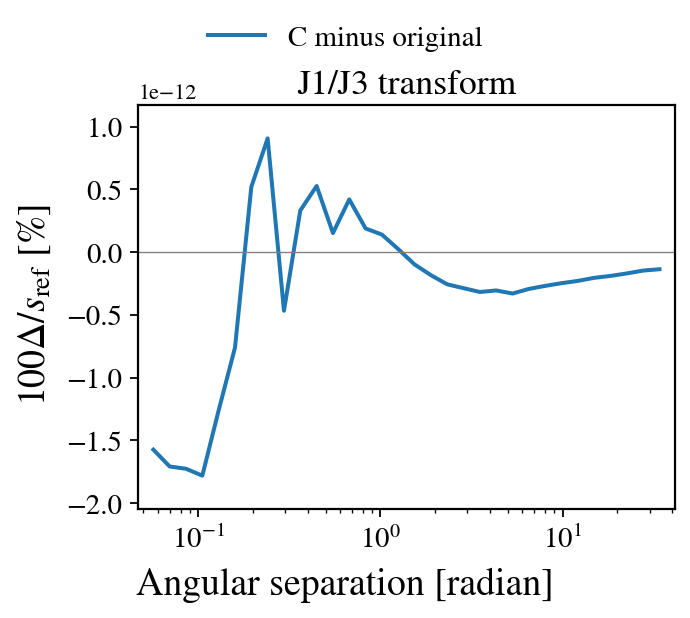

In [4]:
case = comparison_case(report=report, name="bessel_main_taper")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="Angular separation [radian]",
    quantity_label="Two-Bessel transform", residual="scaled",
    xscale="log", show=1,
)


## The public TATT natural-component calculation

The four complex $\Gamma_i$ are three-shear correlations after specified rotations of the shear axes. A smooth symmetric set of bispectrum multipoles is supplied through `set_bispectrum`, the original public interface. Symmetry matters: this branch obtains negative angular modes by transposing positive modes. The port uses its named historical mode for this comparison. General ordered source-bin triplets require the port's independent signed-mode calculation.

Both outputs use centroid projection and the same 200-node linear interpolation for angular coupling. Source table values come from a capped left-endpoint rectangle integral; C table values are analytic. The live zero-integral diagnostic below shows the resulting source bias. A separate saved case, `natural_exact_coupling`, removes interpolation in C and is explicitly a different discretization. Neither residual is a survey accuracy bound. Real and imaginary components are both retained.

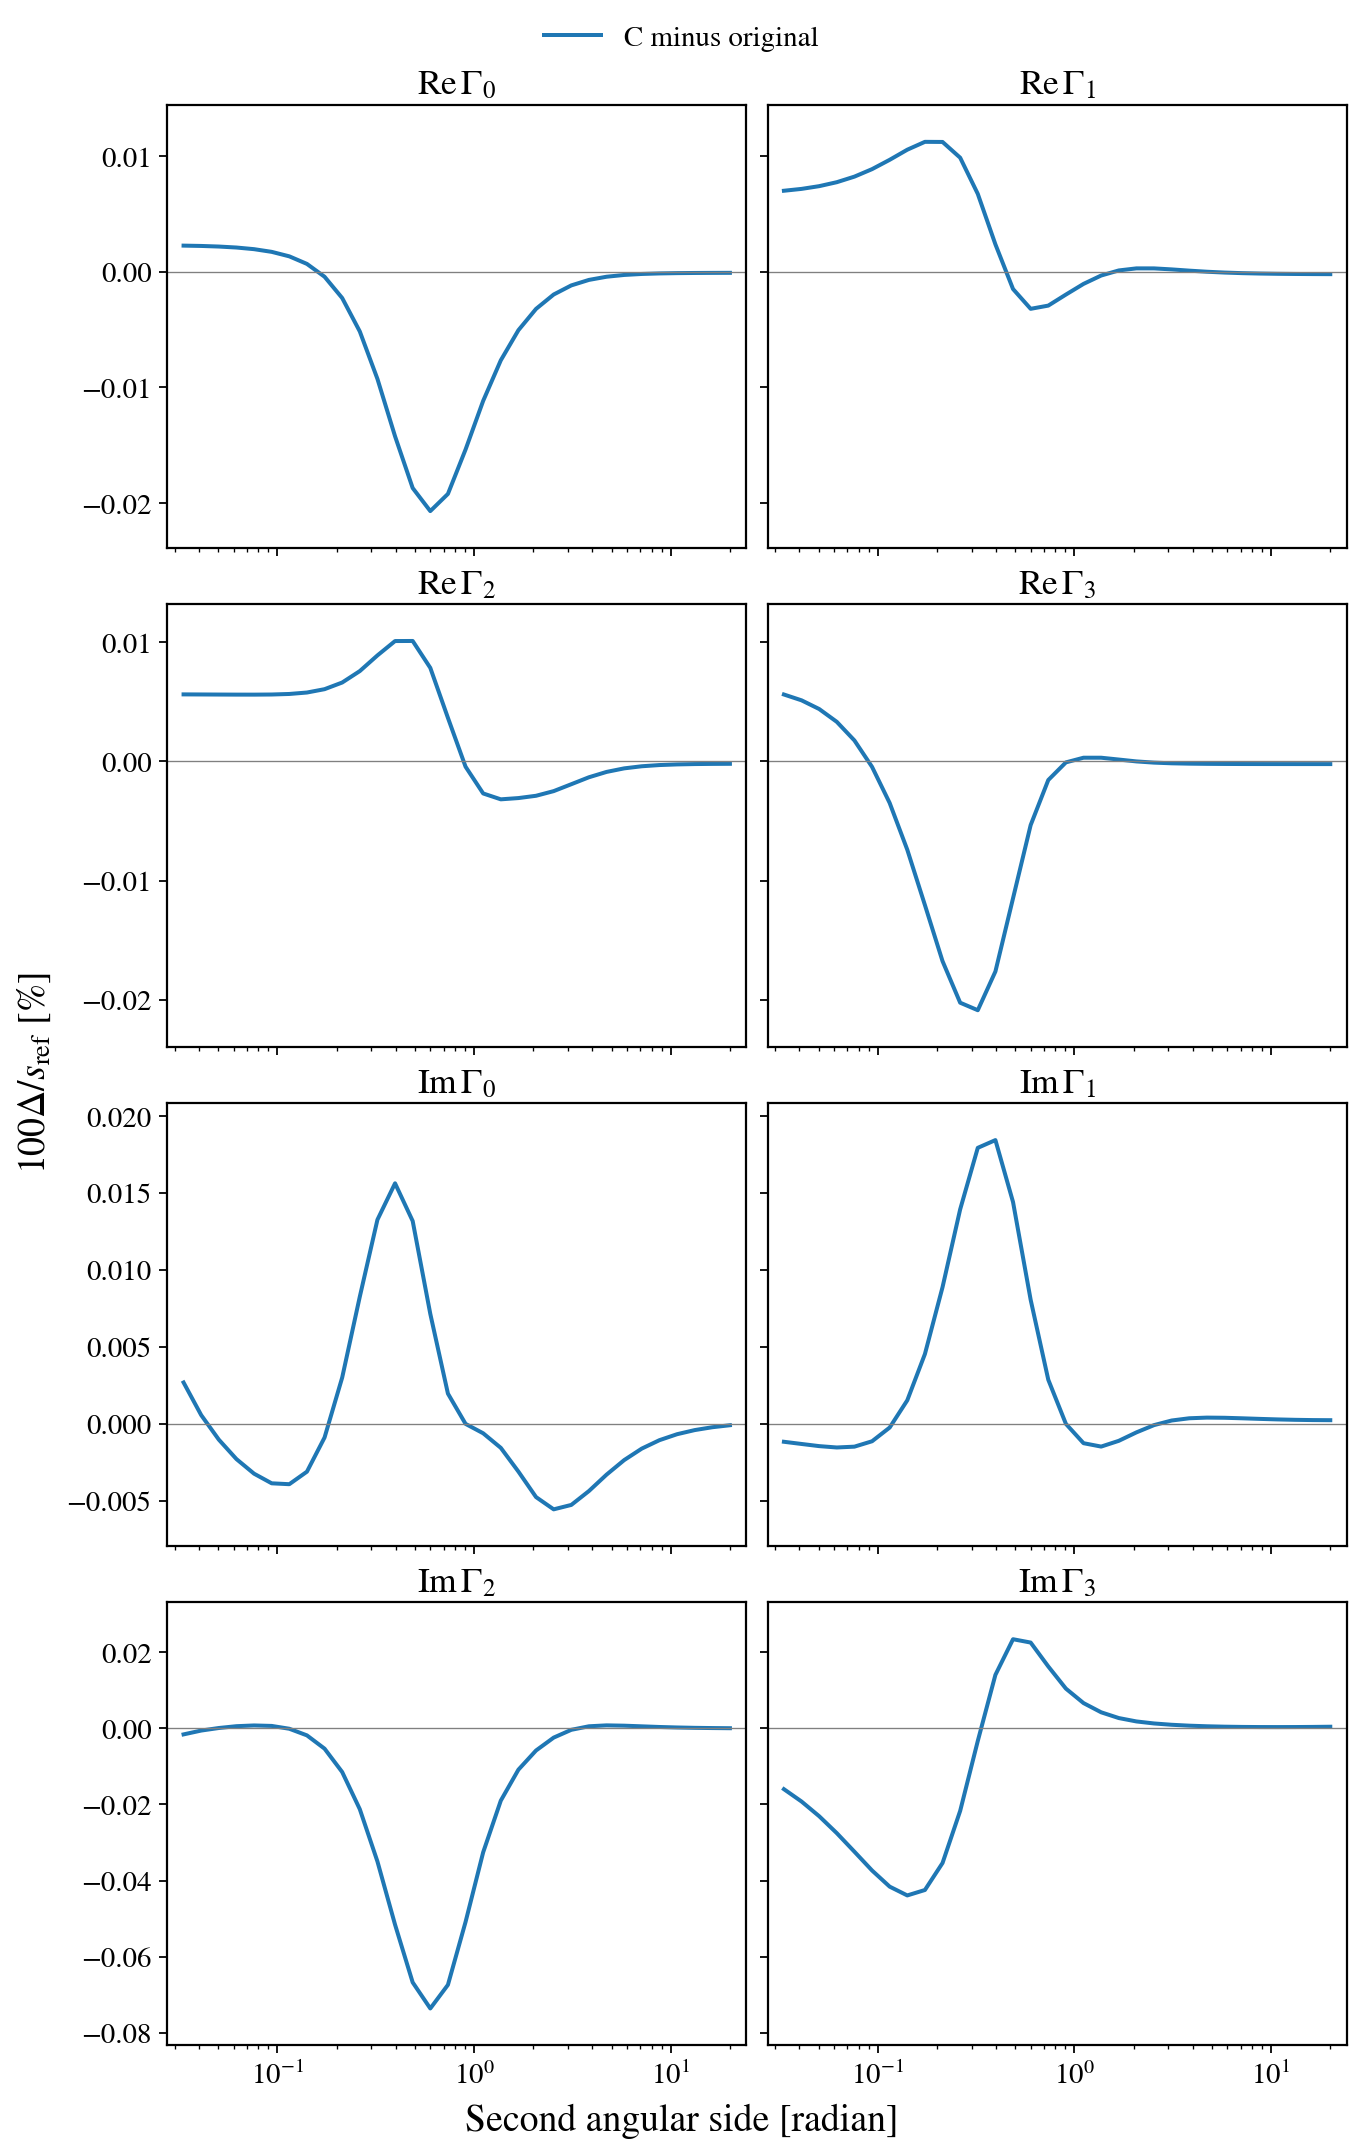

In [5]:
case = comparison_case(report=report, name="natural_tatt_public")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="Second angular side [radian]",
    quantity_label="Natural shear component", residual="scaled",
    xscale="log", ncols=2, show=1,
)


The original coupling integrator reaches its default 4096-sample cap and ignores the convergence flag in its caller. For the known integral $4\pi\int_0^\pi\cos\delta\,d\delta=0$, its left-endpoint sum is $4\pi^2/N$. The following live ladder changes only the public integration-function iteration limit. It isolates this source discretization error without modifying the original code.

In [6]:
coupling_case = comparison_case(report=report, name="coupling_tatt_rectangle_bias")
coupling_case["rectangle_bias_ladder"]


[{'left_rectangle_count': 256,
  'source_integral': 0.15421256876702444,
  'predicted_bias': 0.15421256876702122,
  'converged': False},
 {'left_rectangle_count': 1024,
  'source_integral': 0.038553142191757504,
  'predicted_bias': 0.038553142191755305,
  'converged': False},
 {'left_rectangle_count': 4096,
  'source_integral': 0.009638285547939376,
  'predicted_bias': 0.009638285547938826,
  'converged': False},
 {'left_rectangle_count': 16384,
  'source_integral': 0.002409571386984844,
  'predicted_bias': 0.0024095713869847065,
  'converged': False}]

## Rafael's aperture integral: agreement and a known discrepancy

For equal aperture radii, the original NumPy integral and the C integral should agree for the same finite side/angle grid. The inputs here are already in the component convention expected by that integral; no extra sign or component swap is applied.

The unequal-radius case deliberately exposes an original-source error. The expression `k2.all() == 1` asks whether every ratio is nonzero; it does not ask whether every ratio equals one. Positive unequal ratios therefore select the equal-radius kernel. The original file is run unchanged, while the C calculation uses the general unequal-radius expression. A visible difference in this panel is expected and must not be described as a failed tolerance test.

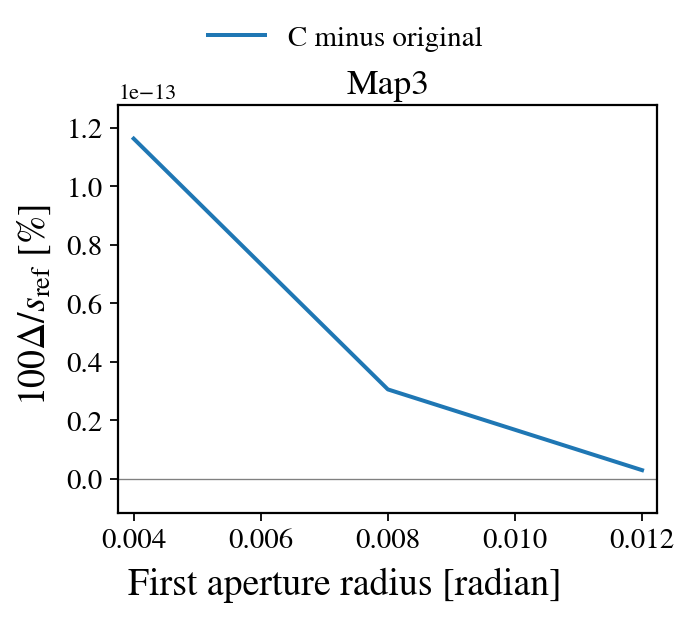

In [7]:
case = comparison_case(report=report, name="aperture_equal")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="First aperture radius [radian]",
    quantity_label="Map3, equal radii", residual="scaled", show=1,
)


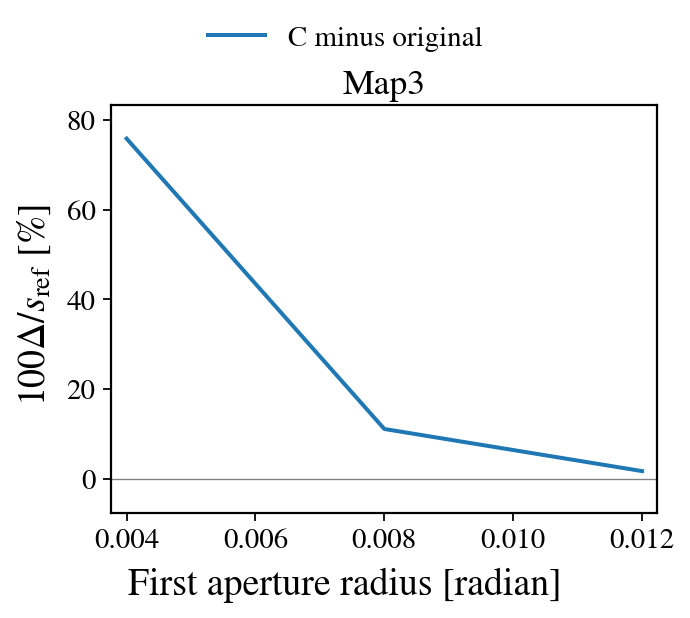

In [8]:
case = comparison_case(report=report, name="aperture_unequal")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="First aperture radius [radian]",
    quantity_label="Map3, unequal radii",
    residual="scaled", show=1,
)


## Frozen physical reference: a different kind of evidence

These matter values were saved from the pinned original Python calculation. This cell runs the C physical model on the fixture's declared smooth power spectra and background, then reads the saved reference. It does **not** run the original matter or IA code live. The table above labels these cases `frozen_reference` and records the fixture hash.

The source nonlinear-radius root has a finite stopping error. Separate tests compare the matter fit with its established allowance, check the analytic tree limit, and evaluate squeezed triangles and all 19 IA terms at high precision. The right-triangle ddB component has an analytic zero, so its machine-roundoff check uses its vertex amplitude rather than a relative tolerance on zero.

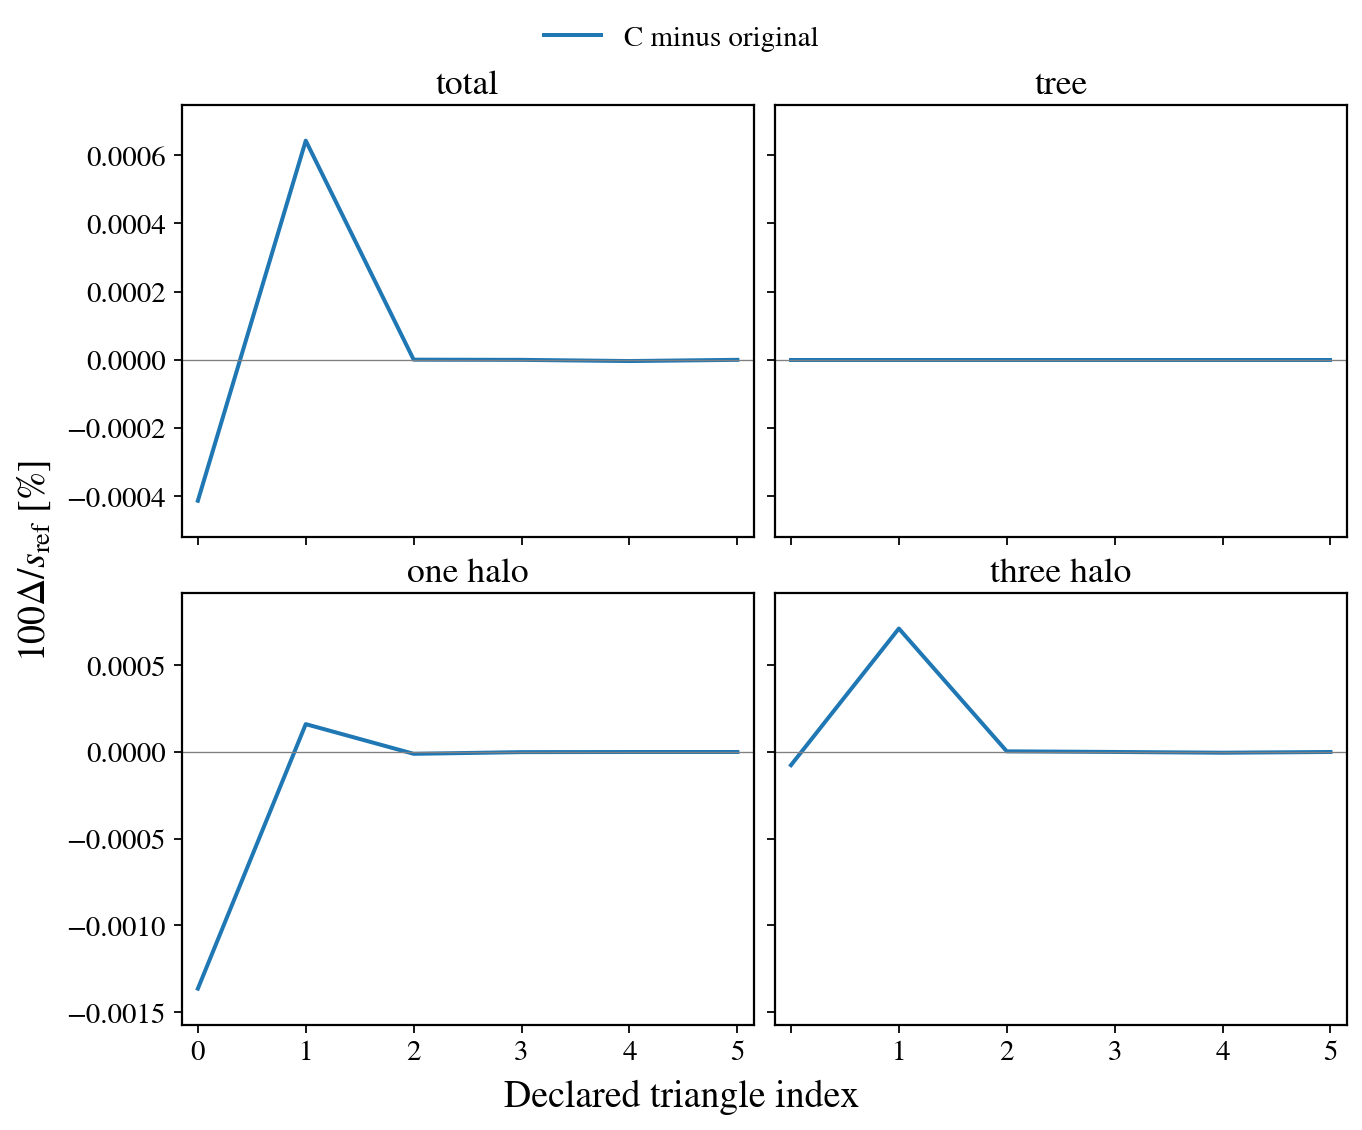

In [9]:
case = comparison_case(report=report, name="physics_matter_frozen")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="Declared triangle index",
    quantity_label="Matter bispectrum [(Mpc/h)^6]",
    residual="scaled", ncols=2, show=1,
)


## What the result establishes

The saved arrays check source identity, Fourier and phase conventions, finite-grid aperture weights, and the port's response to a documented source correction. They do not check a catalogue measurement, a full original CosmoSIS likelihood, survey masks, or final grid convergence. DES results still require the specified estimator, cuts, source distributions, covariance assumptions and numerical error budget.

Credits: fastnc is by Sunao Sugiyama and Rafael Heringer Gomes; the aperture routine is Rafael's adaptation of Mike Jarvis's TreeCorr implementation. Repository pins, hashes and file-level credits are recorded in `data/code_comparison_manifest.json` and [the comparison guide](COMPARISON.md).